In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.svm import SVC

In [2]:
df = pd.read_csv("student-por.csv", sep=';')

print(df.head())

  school sex  age address famsize Pstatus  Medu  Fedu     Mjob      Fjob  ...  \
0     GP   F   18       U     GT3       A     4     4  at_home   teacher  ...   
1     GP   F   17       U     GT3       T     1     1  at_home     other  ...   
2     GP   F   15       U     LE3       T     1     1  at_home     other  ...   
3     GP   F   15       U     GT3       T     4     2   health  services  ...   
4     GP   F   16       U     GT3       T     3     3    other     other  ...   

  famrel freetime  goout  Dalc  Walc health absences  G1  G2  G3  
0      4        3      4     1     1      3        4   0  11  11  
1      5        3      3     1     1      3        2   9  11  11  
2      4        3      2     2     3      3        6  12  13  12  
3      3        2      2     1     1      5        0  14  14  14  
4      4        3      2     1     2      5        0  11  13  13  

[5 rows x 33 columns]


In [3]:
# Feature 1 = Study Time
# Feature 2 = Absences

X = df[['studytime', 'absences']].values

In [4]:
# 0 = Fail
# 1 = Pass

y = (df['G3'] >= 10).astype(int).values

In [5]:
model = SVC(kernel='linear', C=1000)

model.fit(X, y)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1000
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [6]:
w1 = model.coef_[0][0]
w2 = model.coef_[0][1]
b = model.intercept_[0]

print("w1 =", w1)
print("w2 =", w2)
print("b  =", b)

w1 = -3.637978807091713e-12
w2 = -1.4551915228366852e-11
b  = 1.000000000016974


In [7]:
print("\nDecision Boundary:")
print(f"{w1:.4f} x1 + {w2:.4f} x2 + {b:.4f} = 0")


Decision Boundary:
-0.0000 x1 + -0.0000 x2 + 1.0000 = 0


In [8]:
print("\nSupport Vectors:")
print(model.support_vectors_)


Support Vectors:
[[ 1.  2.]
 [ 1.  4.]
 [ 3.  2.]
 [ 1. 12.]
 [ 1.  2.]
 [ 2. 10.]
 [ 1.  2.]
 [ 2. 24.]
 [ 1. 22.]
 [ 1. 16.]
 [ 1.  0.]
 [ 2.  0.]
 [ 2.  0.]
 [ 1.  8.]
 [ 2.  4.]
 [ 1.  2.]
 [ 2.  0.]
 [ 1. 10.]
 [ 3. 14.]
 [ 2.  4.]
 [ 2.  2.]
 [ 1. 14.]
 [ 1. 26.]
 [ 1.  6.]
 [ 1. 14.]
 [ 2. 16.]
 [ 1. 12.]
 [ 1.  8.]
 [ 1.  4.]
 [ 1.  8.]
 [ 3.  0.]
 [ 2.  2.]
 [ 1.  0.]
 [ 1.  0.]
 [ 1.  4.]
 [ 2.  0.]
 [ 2.  4.]
 [ 2.  7.]
 [ 2.  8.]
 [ 1.  8.]
 [ 3.  0.]
 [ 3.  3.]
 [ 2.  0.]
 [ 2.  9.]
 [ 1.  2.]
 [ 2.  0.]
 [ 1.  0.]
 [ 1.  6.]
 [ 3.  6.]
 [ 2. 12.]
 [ 2.  0.]
 [ 1. 12.]
 [ 4.  2.]
 [ 1.  0.]
 [ 2.  9.]
 [ 1.  0.]
 [ 1.  2.]
 [ 2.  8.]
 [ 2.  0.]
 [ 2.  6.]
 [ 2.  4.]
 [ 4.  2.]
 [ 2.  2.]
 [ 1.  5.]
 [ 1.  8.]
 [ 2.  2.]
 [ 1.  2.]
 [ 2.  8.]
 [ 1.  0.]
 [ 1.  0.]
 [ 1.  2.]
 [ 1.  0.]
 [ 1.  4.]
 [ 2.  9.]
 [ 1.  6.]
 [ 1.  4.]
 [ 2.  8.]
 [ 1.  0.]
 [ 2.  2.]
 [ 1.  0.]
 [ 1.  0.]
 [ 3.  5.]
 [ 2.  0.]
 [ 2.  3.]
 [ 1.  0.]
 [ 2.  3.]
 [ 2.  0.]
 [ 2.  0.]
 [ 1.  0.]
 [ 

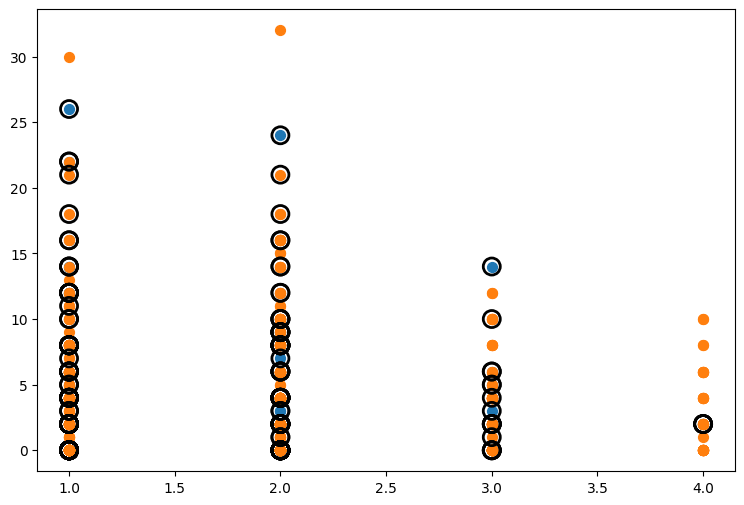

In [9]:
plt.figure(figsize=(9, 6))

# Fail students
plt.scatter(
    X[y == 0, 0],
    X[y == 0, 1],
    s=50,
    label='Fail (Class 0)'
)

# Pass students
plt.scatter(
    X[y == 1, 0],
    X[y == 1, 1],
    s=50,
    label='Pass (Class 1)'
)

# Support vectors
plt.scatter(
    model.support_vectors_[:, 0],
    model.support_vectors_[:, 1],
    s=150,
    facecolors='none',
    edgecolors='black',
    linewidths=2,
    label='Support Vectors'
)

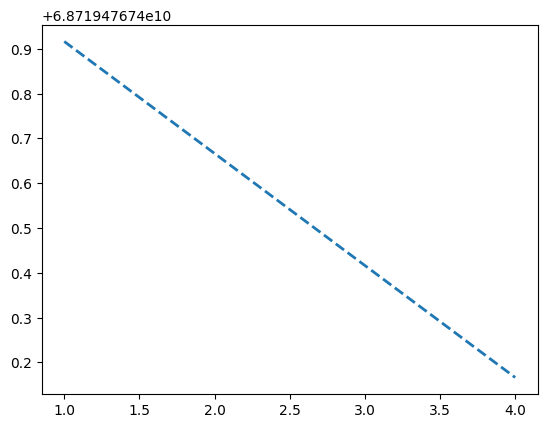

In [10]:
x1_values = np.linspace(
    X[:, 0].min(),
    X[:, 0].max(),
    100
)

# w1*x1 + w2*x2 + b = 0
# x2 = -(w1*x1 + b) / w2

x2_values = -(w1 * x1_values + b) / w2

plt.plot(
    x1_values,
    x2_values,
    linestyle='--',
    linewidth=2,
    label='Decision Boundary'
)

C:\Users\abhis\AppData\Local\Temp\ipykernel_48300\2602887839.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


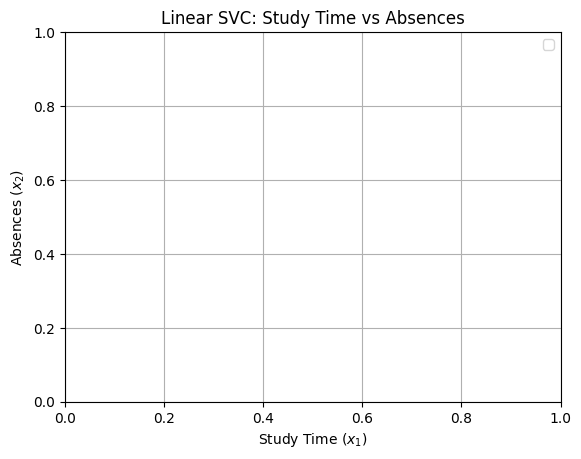

In [11]:
plt.xlabel('Study Time ($x_1$)')
plt.ylabel('Absences ($x_2$)')

plt.title('Linear SVC: Study Time vs Absences')

plt.legend()
plt.grid(True)

plt.show()

In [12]:
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(
    confusion_matrix= cm,
    display_labels=["Fail", "Pass"]
)

disp.plot()

plt.title("SVM Confusion Matrix")
plt.show()

NameError: name 'cm' is not defined